# Fisheye Visual Odometry

Implement a visual odometry pipeline for fisheye drone footage that tracks features with Lucas–Kanade flow and recovers a relative camera trajectory.

This notebook only provides **data paths** and **trajectory evaluation**. The pipeline itself is up to you.

**Deliverables** (all in this notebook):
- Recovered relative trajectory, compared against GT with the evaluation cells below
- All code cells run and plots rendered
- Overlay video
- Summary markdown cell at the end: implementation choices, parameter tuning, observed trajectory quality

In [1]:
from pathlib import Path

import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

import json

from pose_helpers import (
    TrajectoryResult,
    TrajectoryVideoWriter,
    analyze_trajectory,
    draw_tracks,
    plot_trajectory,
    write_video_with_trajectory,
)

plt.rcParams["figure.figsize"] = (14, 6)
plt.rcParams["font.size"] = 11

In [2]:
# --- Data paths ---
PROJECT_ROOT = Path("./flight")
VIDEO_PATH = PROJECT_ROOT / "recording.mp4"
CALIBRATION_PATH = PROJECT_ROOT / "calibration-params.json"
GT_PATH = PROJECT_ROOT / "flight_trajectory_coordinates.csv"

# --- Outputs ---
OVERLAY_VIDEO_PATH = Path("tracks_overlay.mp4")              # written by your pipeline: frames with your tracked points
TRAJECTORY_VIDEO_PATH = Path("tracks_with_trajectory.mp4")   # written by the evaluation: your overlay + trajectory plot

for p in (VIDEO_PATH, CALIBRATION_PATH, GT_PATH):
    if not p.exists():
        raise FileNotFoundError(p)

print(f"Video       : {VIDEO_PATH}")
print(f"Calibration : {CALIBRATION_PATH}")
print(f"Ground truth: {GT_PATH}")

Video       : flight/recording.mp4
Calibration : flight/calibration-params.json
Ground truth: flight/flight_trajectory_coordinates.csv


## Our Pipeline

In [3]:
data = json.loads(CALIBRATION_PATH.read_text())
camera_data = data["cameras"][0]
camera_data

{'distortionCoefficients': [-0.036787647748734414,
  0.004048026529406263,
  -0.007773661433555711,
  0.002068716240417432],
 'focalLengthX': 590.0679459329615,
 'focalLengthY': 589.5248066650331,
 'imageHeight': 1080,
 'imageWidth': 1920,
 'model': 'kannala-brandt4',
 'principalPointX': 1015.0660943015982,
 'principalPointY': 571.3563384482426}

In [4]:
H, W = camera_data["imageHeight"], camera_data["imageWidth"]
fx, fy = camera_data["focalLengthX"], camera_data["focalLengthY"]
cx, cy = camera_data["principalPointX"], camera_data["principalPointY"]

In [5]:
K = np.array([[fx, 0, cx],
              [0, fy, cy],
              [0, 0, 1]])
D = np.array(camera_data["distortionCoefficients"])
distortion_center = K[:, 2]  # principal point (cx, cy)

print("Camera matrix K:\n", K)
print("Distortion coefficients D:\n", D)
print("Distortion center:\n", distortion_center)

Camera matrix K:
 [[5.90067946e+02 0.00000000e+00 1.01506609e+03]
 [0.00000000e+00 5.89524807e+02 5.71356338e+02]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]
Distortion coefficients D:
 [-0.03678765  0.00404803 -0.00777366  0.00206872]
Distortion center:
 [1.01506609e+03 5.71356338e+02 1.00000000e+00]


### Undistort image

(np.float64(-0.5), np.float64(1919.5), np.float64(1079.5), np.float64(-0.5))

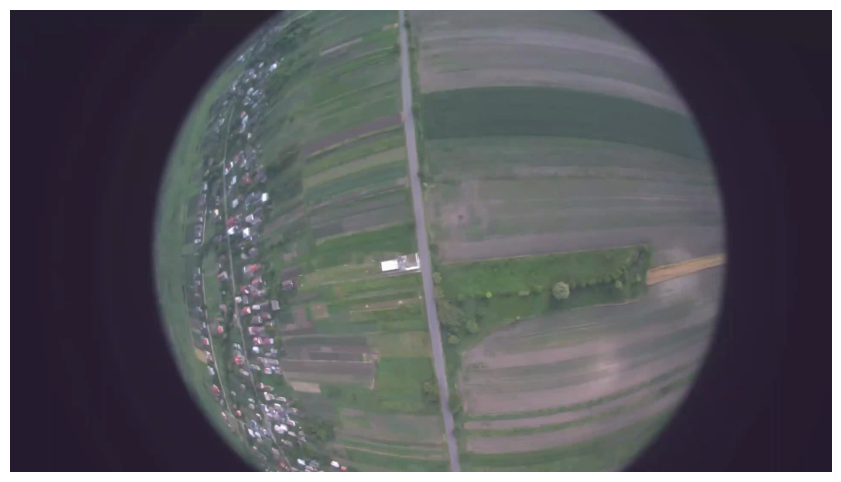

In [6]:
video = cv.VideoCapture(str(VIDEO_PATH))
ok, image = video.read()
assert ok, "frame read failed"
plt.imshow(image[..., ::-1]); plt.axis("off") # BGR to RGB

In [7]:
image.shape

(1080, 1920, 3)

Original K:  [[5.90067946e+02 0.00000000e+00 1.01506609e+03]
 [0.00000000e+00 5.89524807e+02 5.71356338e+02]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]
K_new:  [[5.90067946e+02 0.00000000e+00 1.01506609e+03]
 [0.00000000e+00 5.89524807e+02 5.71356338e+02]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]


(np.float64(-0.5), np.float64(1919.5), np.float64(1079.5), np.float64(-0.5))

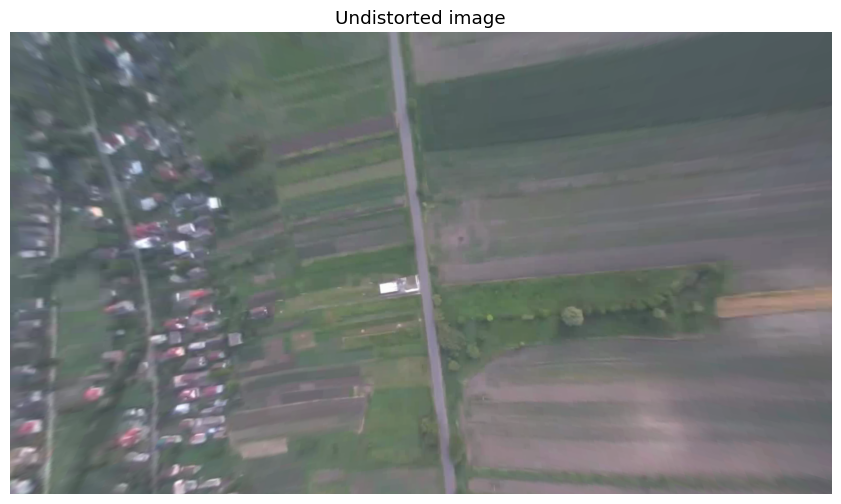

In [8]:
K_new = K.copy()
undistorted_image = cv.fisheye.undistortImage(image, K, D, Knew=K_new)
print("Original K: ", K)
print("K_new: ", K_new)
plt.imshow(undistorted_image[..., ::-1])   # BGR → RGB
plt.title("Undistorted image"); plt.axis("off")

max error: 2.220446049250313e-15


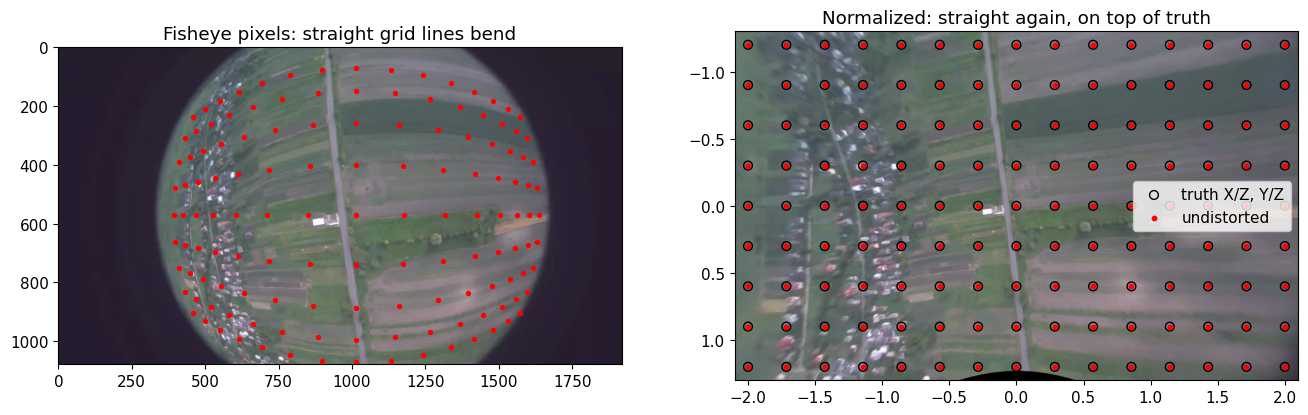

In [9]:
xs, ys = np.meshgrid(np.linspace(-2, 2, 15), np.linspace(-1.2, 1.2, 9))
obj = np.stack([xs.ravel(), ys.ravel(), np.ones(xs.size)], axis=1).reshape(-1, 1, 3)  # float64

img_pts, _ = cv.fisheye.projectPoints(obj, np.zeros(3), np.zeros(3), K, D)
norm = cv.fisheye.undistortPoints(img_pts, K, D)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
ax1.imshow(image[..., ::-1])
ax1.scatter(*img_pts.reshape(-1, 2).T, s=8, c="r",)
ax1.set_title("Fisheye pixels: straight grid lines bend")



H, W = image.shape[:2]
K_new = K.copy()
K_new[0, 0] *= 0.4; K_new[1, 1] *= 0.4          # smaller f → wider view
und = cv.fisheye.undistortImage(image, K, D, Knew=K_new, new_size=(W, H))

fx_new, fy_new, cx_new, cy_new = K_new[0, 0], K_new[1, 1], K_new[0, 2], K_new[1, 2]
extent = [(0 - cx_new) / fx_new, (W - cx_new) / fx_new,          # left, right
          (H - cy_new) / fy_new, (0 - cy_new) / fy_new]          # bottom, top

ax2.set_xlim(-2.1, 2.1)
ax2.set_ylim(1.3, -1.3)     # larger value first, so y keeps pointing down
ax2.imshow(und[..., ::-1], extent=extent)
# ...then your two scatter calls on ax2, as before
ax2.scatter(*obj[:, 0, :2].T, s=40, facecolors="none", edgecolors="k", label="truth X/Z, Y/Z")
ax2.scatter(*norm.reshape(-1, 2).T, s=10, c="r", label="undistorted")
ax2.set_aspect("equal"); ax2.legend()
ax2.set_title("Normalized: straight again, on top of truth")

print("max error:", np.abs(norm.reshape(-1, 2) - obj[:, 0, :2]).max())

In [10]:
def undistort_points(points: np.ndarray, K: np.ndarray, D: np.ndarray) -> np.ndarray:
    """Undistort points using fisheye model.

    Args:
        points: Nx2 array of distorted points (pixel coordinates).
        K: Camera matrix.
        D: Distortion coefficients.

    Returns:
        Nx2 array of undistorted points (pixel coordinates).
    """
    points = points.reshape(-1, 1, 2).astype(np.float64)
    undistorted = cv.fisheye.undistortPoints(points, K, D, P=K)
    return undistorted.reshape(-1, 2)

### Determining image circle
`T = 60` was chosen empirically

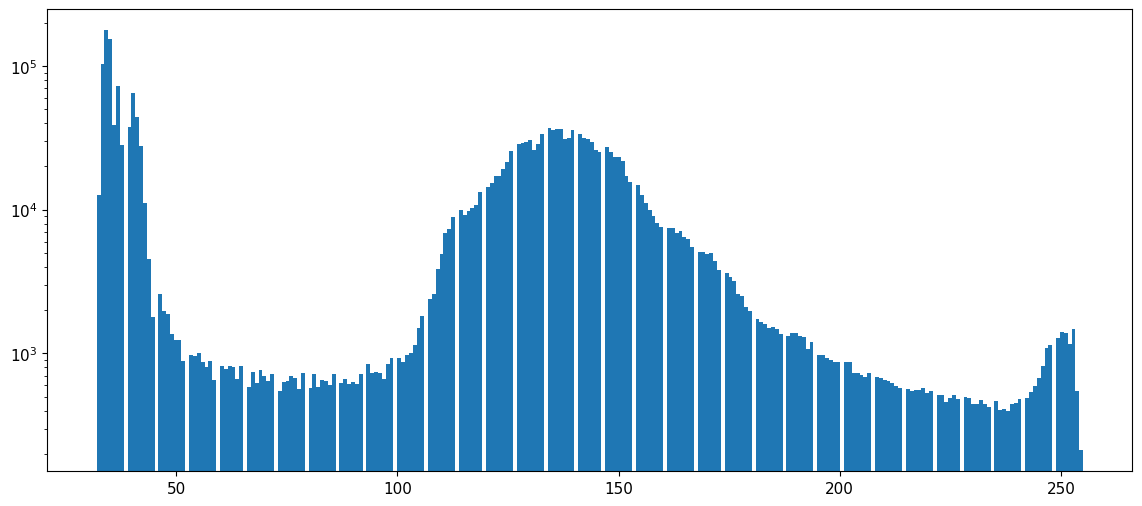

center=(1002.5, 554.8)  R=677.1  principal point=(1015.1, 571.4)


In [11]:
cap = cv.VideoCapture(str(VIDEO_PATH))
n = int(cap.get(cv.CAP_PROP_FRAME_COUNT))


acc = np.zeros((H, W), np.uint8)
for i in np.linspace(0, n - 1, 20, dtype=int):      # 20 frames spread over the video
    cap.set(cv.CAP_PROP_POS_FRAMES, int(i))
    ok, frame = cap.read()
    if not ok:
        continue
    gray = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)
    acc = np.maximum(acc, gray)                      # per-pixel brightest value seen
cap.release()

# Pick T from the data: look where the border values end and the scene begins
plt.hist(acc.ravel(), bins=256, log=True); plt.show()

T = 60
_, bw = cv.threshold(acc, T, 255, cv.THRESH_BINARY)

# Keep only the biggest blob, so a few stray bright pixels can't inflate the circle
contours, _ = cv.findContours(bw, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_NONE)
circle_contour = max(contours, key=cv.contourArea)
(xc, yc), R = cv.minEnclosingCircle(circle_contour)
print(f"center=({xc:.1f}, {yc:.1f})  R={R:.1f}  principal point=({K[0,2]:.1f}, {K[1,2]:.1f})")

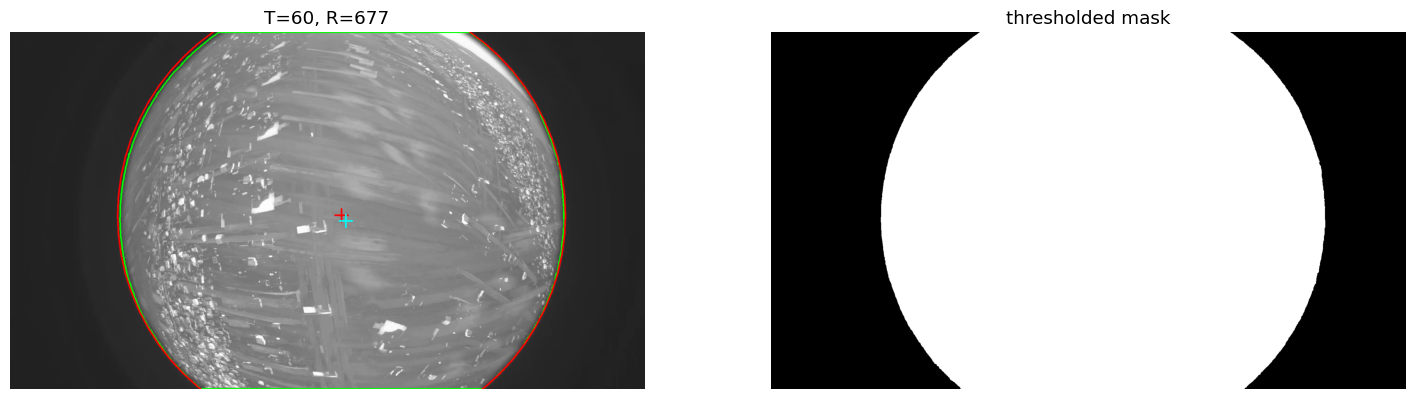

In [12]:
vis = cv.cvtColor(acc, cv.COLOR_GRAY2BGR)              # the max-image; swap in a real frame if you prefer
cv.drawContours(vis, [circle_contour], -1, (0, 255, 0), 3)          # green: the blob's outline
cv.circle(vis, (int(xc), int(yc)), int(R), (0, 0, 255), 3)          # red: enclosing circle
cv.drawMarker(vis, (int(xc), int(yc)), (0, 0, 255), cv.MARKER_CROSS, 40, 3)          # red +: circle center
cv.drawMarker(vis, (int(K[0, 2]), int(K[1, 2])), (255, 255, 0), cv.MARKER_CROSS, 40, 3)  # cyan +: principal point

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))
ax1.imshow(vis[..., ::-1]); ax1.set_title(f"T={T}, R={R:.0f}"); ax1.axis("off")
ax2.imshow(bw, cmap="gray"); ax2.set_title("thresholded mask"); ax2.axis("off")
plt.show()

In [13]:
margin = 40
circle_mask = np.zeros(gray.shape, np.uint8)                  # (1080, 1920), all 0
cv.circle(circle_mask, (int(xc), int(yc)), int(R - margin), 255, thickness=-1) # filled disk = 255
circle_mask.max()

np.uint8(255)

### Features

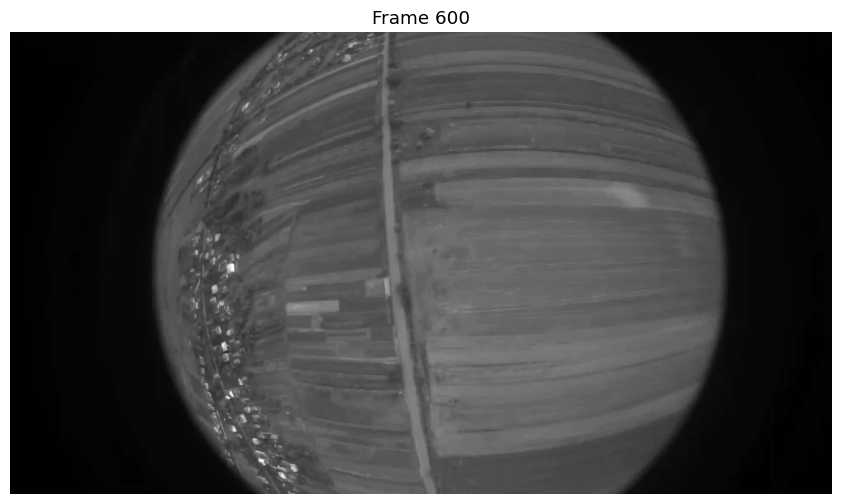

In [14]:
cap = cv.VideoCapture(str(VIDEO_PATH))
i = 600

acc = np.zeros((H, W), np.uint8)
cap.set(cv.CAP_PROP_POS_FRAMES, i)
ok, frame = cap.read()
if not ok:
    raise RuntimeError(f"Failed to read frame {i}")
gray = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)
acc = np.maximum(acc, gray)                      # per-pixel brightest value seen
cap.release()

plt.imshow(acc, cmap="gray"); plt.title(f"Frame {i}"); plt.axis("off"); plt.show()

In [15]:
corners = cv.goodFeaturesToTrack(gray, maxCorners=100, qualityLevel=0.3, minDistance=15, mask=circle_mask)


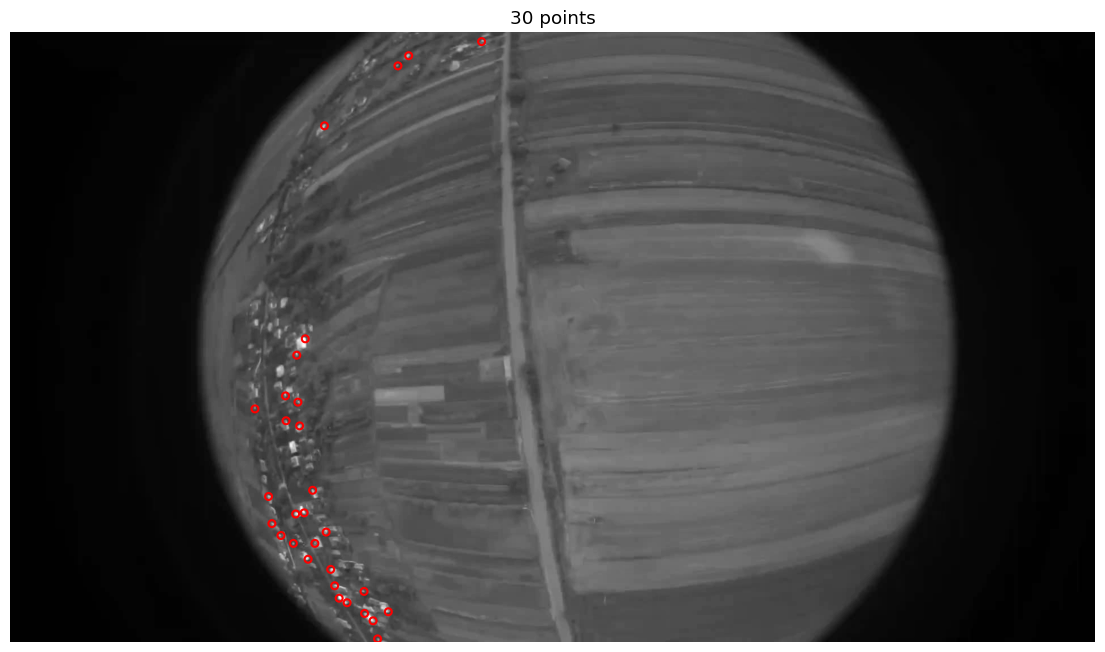

In [16]:
pts = corners.reshape(-1, 2) if corners is not None else np.empty((0, 2))

def plot_points(ax: plt.Axes, gray: np.ndarray, pts: np.ndarray, W: int, H: int) -> None:
    """Plot points on the image and count coverage in 8x6 grid cells.

    Args:
        ax: Matplotlib axes.
        gray: Grayscale image.
        pts: Nx2 array of point points.
        W: Image width.
        H: Image height.
    """

    ax.imshow(gray, cmap="gray")
    ax.scatter(pts[:, 0], pts[:, 1], s=25, facecolors="none", edgecolors="r", linewidths=1.5)

    cells = {(int(x // (W // 8)), int(y // (H // 6))) for x, y in pts}
    ax.set_title(f"{len(pts)} points")
    ax.axis("off")
    plt.show()

fig, ax = plt.subplots(figsize=(14, 8))
plot_points(ax, gray, pts, W, H)

All detected features are on the ege of the image, where the roof tops are. That is a problem, because most of the image does not have any detected features, the field does not have features. 

To address that we crop the image into a grid and detect features in each grid

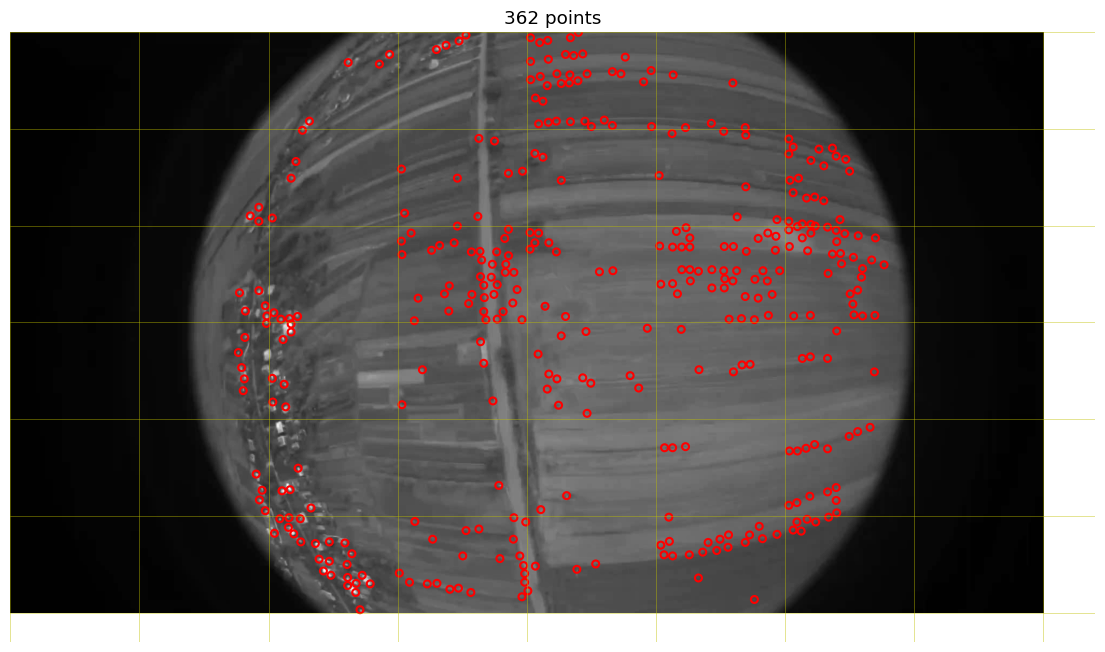

In [17]:
grid_size = (8, 6)

def get_features(gray: np.ndarray, circle_mask: np.ndarray, grid_size: tuple,
                 max_corners: int, quality_level: float, min_distance: int) -> np.ndarray:
    """Detect features in the image using a grid-based approach.

    Args:
        gray: Grayscale image.
        circle_mask: Binary mask of the circular region of interest.
        grid_size: Tuple of (num_cols, num_rows) for the grid.
        max_corners: Maximum number of corners to detect.
        quality_level: Quality level for corner detection.
        min_distance: Minimum distance between corners.

    Returns:
        Nx2 array of detected feature points.
    """
    features = np.array([], dtype=np.float32).reshape(0, 2)  # initialize empty array for features

    for x0, x1 in zip(np.linspace(0, W, grid_size[0] + 1)[:-1], np.linspace(0, W, grid_size[0] + 1)[1:]):
        for y0, y1 in zip(np.linspace(0, H, grid_size[1] + 1)[:-1], np.linspace(0, H, grid_size[1] + 1)[1:]):
            roi = gray[int(y0):int(y1), int(x0):int(x1)]
            roi_mask = circle_mask[int(y0):int(y1), int(x0):int(x1)]

            # skip if the ROI is outside the circle
            if cv.countNonZero(roi_mask) <= roi_mask.size * 0.1:
                continue

            pts = cv.goodFeaturesToTrack(roi, maxCorners=max_corners, qualityLevel=quality_level, minDistance=min_distance, mask=roi_mask)
            if pts is None:
                continue
            pts = pts.reshape(-1, 2)
            features = np.vstack([features, pts + np.array([[x0, y0]])])  # local ROI to image coordinates

    return features

features = get_features(gray, circle_mask, grid_size, max_corners=100, quality_level=0.3, min_distance=15)
fig, ax = plt.subplots(figsize=(14, 8))
# 8×6 grid lines, so you can count coverage by eye
for x in range(0, W + 1, W // grid_size[0]): ax.axvline(x, color="y", lw=0.5, alpha=0.6)
for y in range(0, H + 1, H // grid_size[1]): ax.axhline(y, color="y", lw=0.5, alpha=0.6)
plot_points(ax, gray, features, W, H)

Let's stick with something more strict. Limit the max #corners to not oversaturate on feature-rich textures

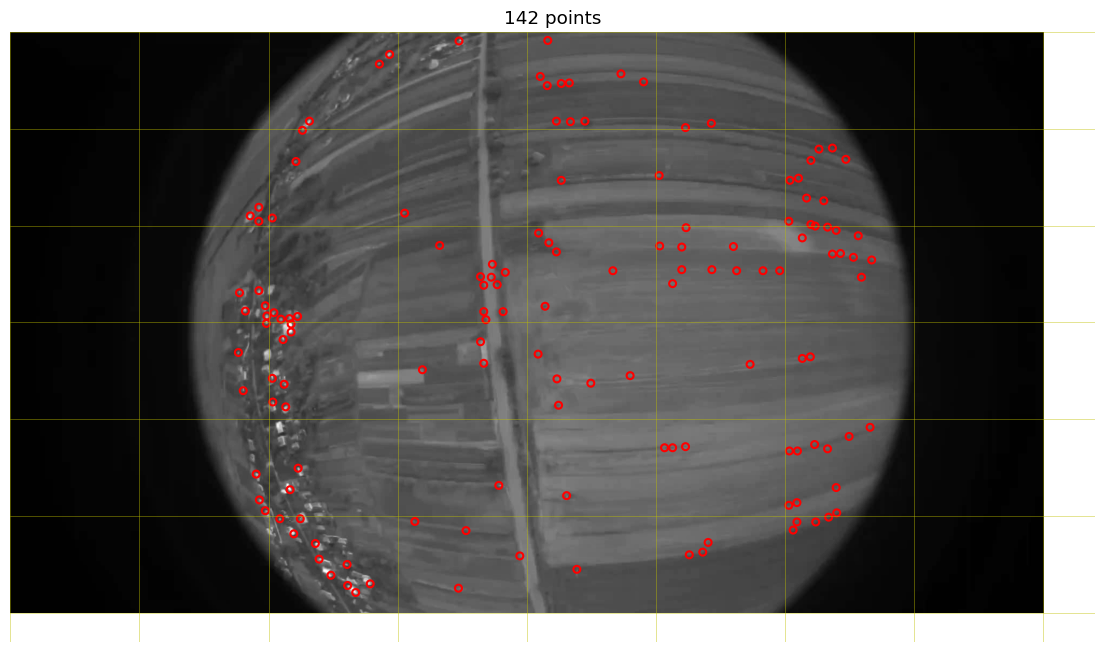

In [18]:
features = get_features(gray, circle_mask, grid_size, max_corners=10, quality_level=0.5, min_distance=15)
fig, ax = plt.subplots(figsize=(14, 8))
# 8×6 grid lines, so you can count coverage by eye
for x in range(0, W + 1, W // grid_size[0]): ax.axvline(x, color="y", lw=0.5, alpha=0.6)
for y in range(0, H + 1, H // grid_size[1]): ax.axhline(y, color="y", lw=0.5, alpha=0.6)
plot_points(ax, gray, features, W, H)

### Lucas-Kanade

In [19]:
cap = cv.VideoCapture(str(VIDEO_PATH))
i = 600

acc = np.zeros((H, W), np.uint8)
cap.set(cv.CAP_PROP_POS_FRAMES, i)
ok, prev_frame = cap.read()
if not ok:
    raise RuntimeError(f"Failed to read prev_frame {i}")
prev_gray = cv.cvtColor(prev_frame, cv.COLOR_BGR2GRAY)
acc = np.maximum(acc, prev_gray)                      # per-pixel brightest value seen

ok, curr_frame = cap.read()
if not ok:
    raise RuntimeError(f"Failed to read curr_frame {i+1}")
curr_gray = cv.cvtColor(curr_frame, cv.COLOR_BGR2GRAY)
acc = np.maximum(acc, curr_gray)                      # per-pixel brightest value seen

cap.release()


features = get_features(prev_gray, circle_mask, grid_size, max_corners=10, quality_level=0.5, min_distance=15)
p0 = features.reshape(-1, 1, 2).astype(np.float32)

Tracked 142 points from frame 600 to frame 601
Error: [1.38569450e+00 2.26749992e+00 1.81583333e+00 1.76527774e+00
 2.24236107e+00 1.79319441e+00 1.35513890e+00 1.53236115e+00
 8.64444435e-01 1.72638893e+00 7.85555542e-01 2.29958344e+00
 1.80069447e+00 2.47305560e+00 1.54013884e+00 1.93722224e+00
 9.39305544e-01 1.74055552e+00 8.33055556e-01 1.16305554e+00
 9.49583352e-01 1.52263892e+00 1.86611116e+00 1.16638887e+00
 1.44375002e+00 1.58749998e+00 1.35208333e+00 1.68347228e+00
 1.25000000e+00 1.87625003e+00 1.51458335e+00 3.15194440e+00
 2.05999994e+00 2.46513891e+00 2.59347224e+00 1.25722218e+00
 1.79527783e+00 2.33666658e+00 1.82319450e+00 1.92930555e+00
 1.81138885e+00 1.88263893e+00 2.83263898e+00 2.64222217e+00
 8.80555570e-01 9.85000014e-01 4.62777764e-01 3.55833322e-01
 2.76527792e-01 2.27500007e-01 4.44444455e-03 4.56111103e-01
 4.03611124e-01 6.59444451e-01 6.05555549e-02 7.31944442e-01
 2.14305550e-01 5.73472202e-01 1.45305550e+00 7.80555546e-01
 1.00805557e+00 1.11916661e+00 

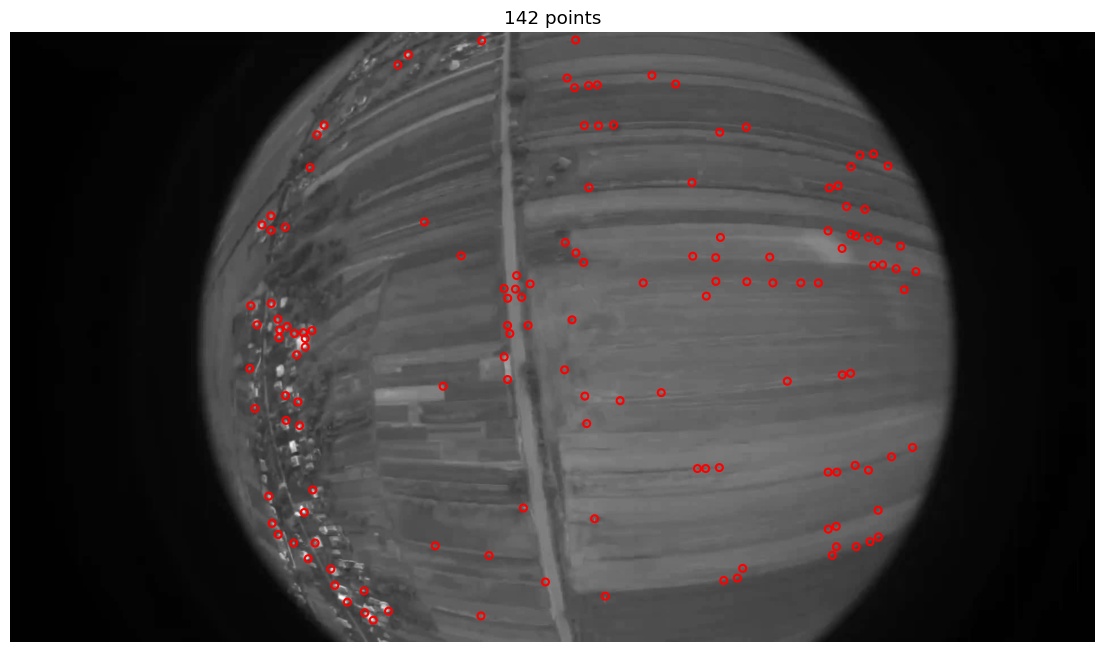

In [20]:
lk_params = dict(
    winSize=(15, 15),
    maxLevel=2,
    criteria=(cv.TERM_CRITERIA_EPS | cv.TERM_CRITERIA_COUNT, 10, 0.03))

p1, st, err = cv.calcOpticalFlowPyrLK(prev_gray, curr_gray, p0, None, **lk_params)
#   p1:  (N, 1, 2) float32, new positions
#   st:  (N, 1) uint8, 1 = converged
#   err: (N, 1) float32, patch dissimilarity (not used here)

if st.all() != 1:
    raise RuntimeError("Optical flow failed to find any points.")

print(f"Tracked {p1.shape[0]} points from frame {i} to frame {i+1}")
print(f"Error: {err.flatten()}")

fg, ax = plt.subplots(figsize=(14, 8))
plot_points(ax, curr_gray, p1.reshape(-1, 2), W, H)


fresh corners: 143, tracked: 142, matched (< 3.0px): 104
tracked  → median 0.51px, p90 1.03px
baseline → median 1.00px  (same points, no tracking)


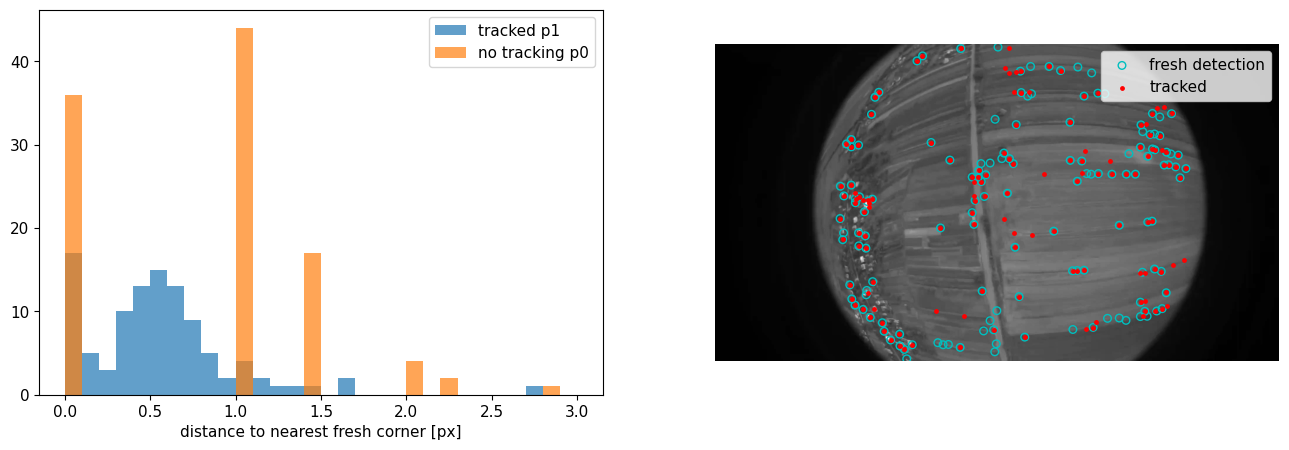

In [21]:
# Fresh detection on the new frame = "reference"
ref = get_features(curr_gray, circle_mask, grid_size, 10, 0.5, 15).reshape(-1, 2)

def nearest_dist(a, b):
    """For each point in a (N,2), distance to its nearest point in b (M,2)."""
    d = np.linalg.norm(a[:, None, :] - b[None, :, :], axis=2)   # (N, M) all pairwise distances
    return d.min(axis=1)

trk = p1.reshape(-1, 2)[st.ravel() == 1]
before = p0.reshape(-1, 2)[st.ravel() == 1]

d_trk = nearest_dist(trk, ref)        # tracked points → fresh corners
d_base = nearest_dist(before, ref)    # untracked (old) positions → fresh corners

match_r = 3.0                          # px: closer than this counts as "the same corner"
m = d_trk < match_r
print(f"fresh corners: {len(ref)}, tracked: {len(trk)}, matched (< {match_r}px): {m.sum()}")
print(f"tracked  → median {np.median(d_trk[m]):.2f}px, p90 {np.percentile(d_trk[m], 90):.2f}px")
print(f"baseline → median {np.median(d_base[m]):.2f}px  (same points, no tracking)")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))
bins = np.linspace(0, match_r, 31)
ax1.hist(d_trk[m], bins, alpha=0.7, label="tracked p1")
ax1.hist(d_base[m], bins, alpha=0.7, label="no tracking p0")
ax1.set_xlabel("distance to nearest fresh corner [px]"); ax1.legend()

ax2.imshow(curr_gray, cmap="gray")
ax2.scatter(*ref.T, s=30, facecolors="none", edgecolors="c", label="fresh detection")
ax2.scatter(*trk.T, s=6, c="r", label="tracked")
ax2.legend(); ax2.axis("off")
plt.show()

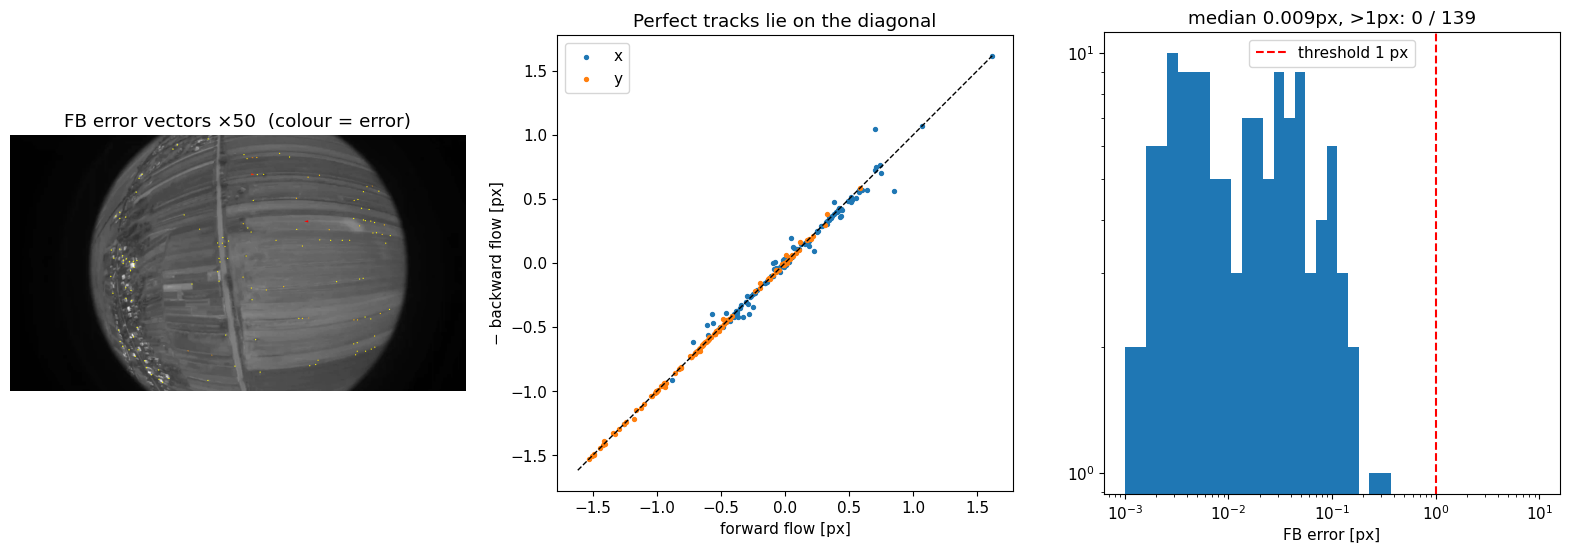

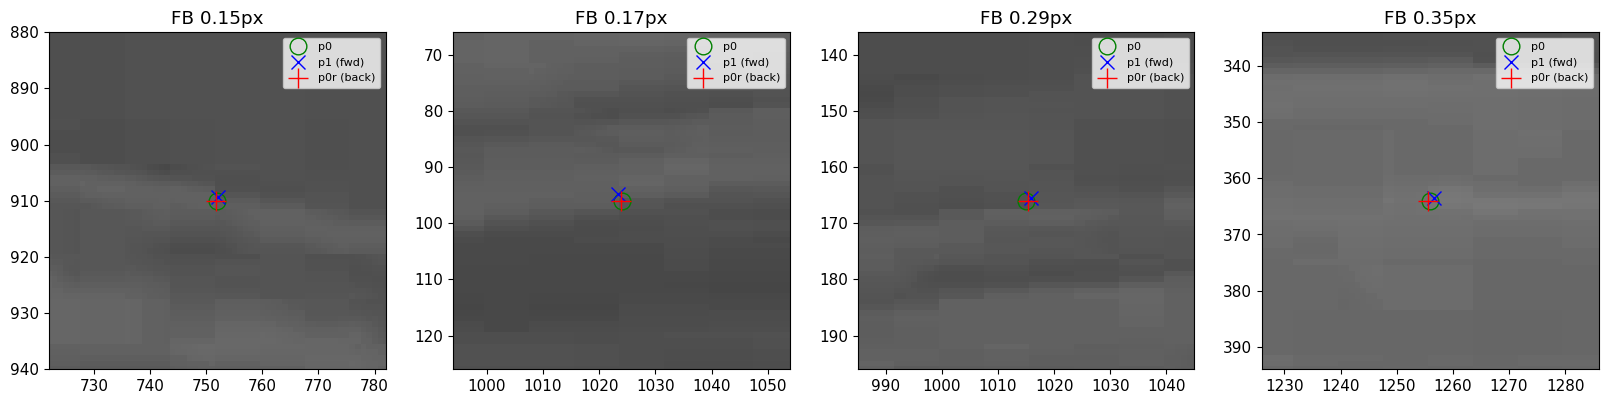

In [22]:
p0r, st_b, _ = cv.calcOpticalFlowPyrLK(curr_gray, prev_gray, p1, None, **lk_params)
fb = np.linalg.norm((p0 - p0r).reshape(-1, 2), axis=1)       # (N,) FB error in px
ok = (st.ravel() == 1) & (st_b.ravel() == 1)
a  = p0.reshape(-1, 2)[ok]          # original
b  = p1.reshape(-1, 2)[ok]          # forward result
ar = p0r.reshape(-1, 2)[ok]         # back to frame A
e  = fb[ok]

fwd = b - a                         # forward flow  A → B
bwd = ar - b                        # backward flow B → A  (should be ≈ −fwd)

fig, axs = plt.subplots(1, 3, figsize=(20, 6))

# 1) Where do points come back? FB error vectors, magnified
amp = 50
axs[0].imshow(prev_gray, cmap="gray")
axs[0].quiver(a[:, 0], a[:, 1], (ar - a)[:, 0] * amp, (ar - a)[:, 1] * amp, e,
              cmap="autumn_r", angles="xy", scale_units="xy", scale=1, width=0.003)
axs[0].set_title(f"FB error vectors ×{amp}  (colour = error)")
axs[0].axis("off")

# 2) Do the two flows cancel? forward vs −backward, per component
axs[1].scatter(fwd[:, 0], -bwd[:, 0], s=8, label="x")
axs[1].scatter(fwd[:, 1], -bwd[:, 1], s=8, label="y")
lim = np.abs(np.r_[fwd.ravel(), bwd.ravel()]).max()
axs[1].plot([-lim, lim], [-lim, lim], "k--", lw=1)
axs[1].set_xlabel("forward flow [px]"); axs[1].set_ylabel("− backward flow [px]")
axs[1].set_aspect("equal"); axs[1].legend()
axs[1].set_title("Perfect tracks lie on the diagonal")

# 3) FB error distribution
axs[2].hist(e, bins=np.logspace(-3, 1, 40), log=True)
axs[2].set_xscale("log"); axs[2].axvline(1.0, color="r", ls="--", label="threshold 1 px")
axs[2].set_xlabel("FB error [px]"); axs[2].legend()
axs[2].set_title(f"median {np.median(e):.3f}px, >1px: {(e > 1).sum()} / {len(e)}")
plt.show()

# 4) Zoom on the worst few: original (o), forward (x), returned (+)
worst = np.argsort(e)[-4:]
fig, axs = plt.subplots(1, 4, figsize=(20, 5))
for ax, k in zip(axs, worst):
    x, y = a[k]
    ax.imshow(prev_gray, cmap="gray")
    ax.plot(*a[k], "go", mfc="none", ms=12, label="p0")
    ax.plot(*b[k], "bx", ms=10, label="p1 (fwd)")
    ax.plot(*ar[k], "r+", ms=14, label="p0r (back)")
    ax.set_xlim(x - 30, x + 30); ax.set_ylim(y + 30, y - 30)
    ax.set_title(f"FB {e[k]:.2f}px"); ax.legend(fontsize=8)
plt.show()

### Motion estimation

Fit a homography in normalized coordinates, then select a ground-facing, positive-depth decomposition consistent with the previous rotation.

| Parameter | Meaning |
| :-- | :-- |
| `threshold=0.002` | RANSAC reprojection error in normalized coordinates, about 1.2 px near the image centre. |
| `12` | Minimum correspondences and inliers; more than the four needed to fit a homography. |
| Ray radius `<3` | Exclude unstable rays near the fisheye horizon. |
| Normal z `≥0.2`, positive depth `≥95%` | Reject backward-facing planes and physically implausible solutions. |
| `0.1` | Soft rotation-continuity weight; translation can still stop or reverse. |
| `2000`, `0.999` | RANSAC iteration limit and confidence. |

In [23]:
def estimate_motion(a, b, previous_R, threshold=0.002):
    inliers = np.zeros(len(a), bool)
    valid = np.isfinite(a).all(axis=1) & np.isfinite(b).all(axis=1)
    valid &= (np.linalg.norm(a, axis=1) < 3) & (np.linalg.norm(b, axis=1) < 3)
    a, b = a[valid], b[valid]
    if len(a) < 12:
        return np.eye(3), np.zeros(3), inliers
    H_pair, mask = cv.findHomography(a, b, cv.RANSAC, threshold, maxIters=2000, confidence=0.999)
    if H_pair is None or mask.sum() < 12:
        return np.eye(3), np.zeros(3), inliers
    _, rotations, translations, normals = cv.decomposeHomographyMat(H_pair, np.eye(3))
    rays = np.column_stack((a[mask.ravel() == 1], np.ones(int(mask.sum()))))
    candidates = []
    for R, t, normal in zip(rotations, translations, normals):
        t, normal = t.ravel(), normal.ravel()
        if np.linalg.norm(normal) < 1e-8:
            normal = np.array([0., 0., 1.])
        depth = rays @ normal
        if normal[2] < 0.2 or np.any(np.abs(depth) < 1e-8):
            continue
        transformed = (rays / depth[:, None]) @ R.T + t
        if np.mean((depth > 0) & (transformed[:, 2] > 0)) < 0.95:
            continue
        score = 1 - normal[2] + 0.1 * np.linalg.norm(R - previous_R)
        candidates.append((score, R, t))
    if not candidates:
        return np.eye(3), np.zeros(3), inliers
    _, R, t = min(candidates, key=lambda candidate: candidate[0])
    u, _, vt = np.linalg.svd(R)
    R = u @ vt
    inliers[np.flatnonzero(valid)] = mask.ravel().astype(bool)
    return R, t, inliers

### Trajectory

Track consecutive frames and chain inverse camera motions. Scale is relative; x points right and y up in the first image.

OpenCV returns scene motion, `H = R + (t/d)nᵀ`. Camera motion uses its inverse: `Q_next = Q @ R.T`, `C_next = C - Q_next @ t * d`. The initial ground plane is `z=1`, so `d = 1 - C.z`; keeping this factor preserves relative scale as height changes. Rejected pairs hold the last pose.

LK uses the existing settings with a 1 px forward–backward limit. Replenish features below 100 tracks or every 20 frames.

In [24]:
def add_features(gray, points):
    detection_mask = circle_mask.copy()
    for x, y in points:
        cv.circle(detection_mask, (int(round(x)), int(round(y))), 15, 0, -1)
    detected = get_features(gray, detection_mask, grid_size, 10, 0.5, 15)
    combined = np.vstack((points, detected)).astype(np.float32)
    cells = (combined // [W / grid_size[0], H / grid_size[1]]).astype(int)
    keep = np.zeros(len(combined), bool)
    for cell in np.unique(cells, axis=0):
        indices = np.flatnonzero((cells == cell).all(axis=1))
        keep[indices[:max(10, int(np.sum(indices < len(points))))]] = True
    return combined[keep]

## Pipeline results

The evaluation below expects two things.

**1. A `traj_result: TrajectoryResult`** with:

| Field | Shape | Meaning |
| :-- | :-- | :-- |
| `positions` | `(N + 1, ≥2)` array | Row 0 is the starting pose; row `i + 1` is the pose at `frame_indices[i]`. Only X and Y are evaluated. |
| `frame_indices` | `N` ints | Absolute frame index in `recording.mp4` of each recovered pose (used to match GT rows). |
| `inliers` | `N` ints | Inlier count of the motion estimate for each recovered pose. |
| `timestamps` | `N` floats | Time of each recovered pose, in seconds. |

**2. An overlay video at `OVERLAY_VIDEO_PATH`** with one frame per frame of `recording.mp4`, in the same order (frame `k` of the overlay = frame `k` of the recording). `write_video_with_trajectory` seeks into it by `frame_indices`. `TrajectoryVideoWriter` and `draw_tracks` from `pose_helpers` can do this for you.

In [25]:
cv.setRNGSeed(0)
cv.setNumThreads(4)
cap = cv.VideoCapture(str(VIDEO_PATH))
fps = cap.get(cv.CAP_PROP_FPS)
ok, frame = cap.read()
if not ok:
    raise RuntimeError("Cannot read first frame")
prev_gray = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)
points = add_features(prev_gray, np.empty((0, 2), np.float32))
position, orientation, previous_R = np.zeros(3), np.eye(3), np.eye(3)
positions, inlier_counts, frame_indices, timestamps, tracks = [position.copy()], [], [], [], [None]
frame_idx = 0
try:
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        frame_idx += 1
        gray = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)
        a, b = np.empty((0, 2), np.float32), np.empty((0, 2), np.float32)
        if len(points):
            p0 = points.reshape(-1, 1, 2)
            p1, st, _ = cv.calcOpticalFlowPyrLK(prev_gray, gray, p0, None, **lk_params)
            if p1 is not None:
                back, st_back, _ = cv.calcOpticalFlowPyrLK(gray, prev_gray, p1, None, **lk_params)
                if back is not None:
                    good = (st.ravel() == 1) & (st_back.ravel() == 1)
                    good &= np.isfinite(p1.reshape(-1, 2)).all(axis=1)
                    good &= np.linalg.norm((p0 - back).reshape(-1, 2), axis=1) < 1
                    b_all = p1.reshape(-1, 2)
                    good &= (b_all[:, 0] >= 0) & (b_all[:, 0] < W) & (b_all[:, 1] >= 0) & (b_all[:, 1] < H)
                    indices = np.flatnonzero(good)
                    good[indices] &= circle_mask[b_all[indices, 1].astype(int), b_all[indices, 0].astype(int)] > 0
                    a, b = p0.reshape(-1, 2)[good], b_all[good]
        R_step, t_step, mask = np.eye(3), np.zeros(3), np.zeros(len(a), bool)
        if len(a) >= 12:
            a_norm = cv.fisheye.undistortPoints(a.reshape(-1, 1, 2).astype(float), K, D).reshape(-1, 2)
            b_norm = cv.fisheye.undistortPoints(b.reshape(-1, 1, 2).astype(float), K, D).reshape(-1, 2)
            R_step, t_step, mask = estimate_motion(a_norm, b_norm, previous_R)
        orientation = orientation @ R_step.T
        position = position - orientation @ t_step * (1 - position[2])
        previous_R = R_step if mask.any() else previous_R
        positions.append(position * [1, -1, -1])
        frame_indices.append(frame_idx)
        timestamps.append(frame_idx / fps)
        inlier_counts.append(int(mask.sum()))
        tracks.append((a, b, mask))
        points, prev_gray = b, gray
        if len(points) < 100 or frame_idx % 20 == 0:
            points = add_features(gray, points)
finally:
    cap.release()
traj_result = TrajectoryResult(timestamps, np.asarray(positions), inlier_counts, frame_indices)
print(f"{len(frame_indices)} poses, {np.count_nonzero(inlier_counts)} accepted motions")

3560 poses, 2777 accepted motions


## Evaluation

Do not modify. Checks the result format, plots the trajectory and inliers, renders the trajectory video, and compares against GT.

In [26]:
assert isinstance(traj_result, TrajectoryResult), "traj_result must be a TrajectoryResult"
n = len(traj_result.frame_indices)
assert n > 0, "No poses recovered"
assert traj_result.positions.shape[0] == n + 1, "positions must have len(frame_indices) + 1 rows"
assert len(traj_result.inliers) == n and len(traj_result.timestamps) == n, "inliers/timestamps must match frame_indices"
assert OVERLAY_VIDEO_PATH.exists(), f"Overlay video not found: {OVERLAY_VIDEO_PATH}"
print(f"Recovered {n} poses")

plot_trajectory(traj_result)

AssertionError: Overlay video not found: tracks_overlay.mp4

In [ ]:
write_video_with_trajectory(
    OVERLAY_VIDEO_PATH,
    traj_result,
    output_path=TRAJECTORY_VIDEO_PATH,
    stride=5,
)

In [ ]:
analyze_trajectory(traj_result, GT_PATH)

## Summary

**Implementation choices:** _..._

**Parameter tuning:** _which parameters you tuned, what you tried, and the evidence from your run that justified the final values._

**Trajectory quality and overlay video:** _how close the result is to GT, where it drifts or fails, and why._